# 2.3 — Computer-Vision Pixel Ratio Analysis

Runs the same statistical battery as notebook 2.2 (physical dimensions from
`artifacts.csv`) but on **pixel-based height/width ratios** extracted from
silhouette images via the largest-connected-component pipeline.

Data source: `h_w_ratio_df_all.csv` from Zenodo (DOI: 10.5281/zenodo.12787745).

## Why compare to physical dimensions?
Physical measurements (notebook 2.2) are available for ~83,745 tablets and
were recorded manually. Pixel ratios cover all 94,936 images but are affected
by composite image layouts and camera framing. Comparing the two reveals:
- How much additional coverage computer vision provides
- Whether the pixel-ratio trend replicates the physical-measurement trend
- Which periods show the greatest divergence (potential confound flags)

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches
import seaborn as sns
from scipy.stats import kruskal, mannwhitneyu, spearmanr

warnings.filterwarnings('ignore', category=FutureWarning)

FIGURES_DIR = 'paper/figures'
ZENODO_BASE = 'https://zenodo.org/records/12787746/files'
os.makedirs(FIGURES_DIR, exist_ok=True)

plt.rcParams.update({
    'font.family': 'serif', 'font.size': 9,
    'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8, 'ytick.labelsize': 8,
    'legend.fontsize': 8, 'figure.dpi': 150, 'savefig.dpi': 300,
})
print('Setup complete.')

Setup complete.


## 1. Load data

Download pixel ratio file from Zenodo and join with `artifacts.csv`
to attach period, genre, and millennium metadata.

In [2]:
pixel_url = f'{ZENODO_BASE}/h_w_ratio_df_all.csv'
print(f'Loading: {pixel_url}')
pix = pd.read_csv(pixel_url)
print(f'Pixel ratio rows: {len(pix):,}')
print(f'Columns: {list(pix.columns)}')
print(pix.head(3))

Loading: https://zenodo.org/records/12787746/files/h_w_ratio_df_all.csv
Pixel ratio rows: 94,936
Columns: ['tablet_p_id_CDLI', 'height', 'width', 'hw_ratio']
  tablet_p_id_CDLI  height  width  hw_ratio
0          P001342     181    182      0.99
1          P001340     171    123      1.39
2          P001330     174    121      1.44


In [3]:
meta = pd.read_csv(
    'artifacts.csv',
    usecols=['artifact_id', 'period', 'genres', 'height', 'width'],
    low_memory=False
)

# Strip leading 'P' and convert to int to match artifact_id
pix['artifact_id'] = pix['tablet_p_id_CDLI'].str.lstrip('P').astype(int)
df = pix.merge(meta, on='artifact_id', how='left')
print(f'After join: {len(df):,} rows, {df["period"].notna().sum():,} with period metadata')

After join: 94,936 rows, 94,278 with period metadata


In [4]:
period_extract = df['period'].str.extract(r'^([^\(]+?)\s*(?:\(|$)')
df['Period_Name'] = period_extract[0].str.strip()
df.loc[df['Period_Name'] == 'Middle Hittite', 'Period_Name'] = 'Hittite'

def normalise_genre(g):
    if pd.isna(g): return 'Other/uncertain'
    g = str(g).lower()
    if any(t in g for t in ['administrative','account','list or inventory','label']): return 'Administrative'
    if 'letter' in g: return 'Letter'
    if any(t in g for t in ['legal','judicial','law','business','contract','lease','loan','oath']): return 'Legal'
    if any(t in g for t in ['literary','epic','hymn','lament','prayer','incantation','ritual','canonical']): return 'Literary'
    if any(t in g for t in ['lexical','vocabulary','word list','sign list']): return 'Lexical'
    if any(t in g for t in ['mathematical','metrological']): return 'Mathematical'
    if any(t in g for t in ['astral','astrology','astronomical','divination','omen']): return 'Astronomical/Divination'
    if any(t in g for t in ['royal','official','display','annals','chronicle','monumental']): return 'Royal/Monumental'
    if 'school' in g: return 'School'
    return 'Other/uncertain'

df['Genre_Name'] = df['genres'].apply(normalise_genre)

THIRD_MIL  = {'Uruk III','Uruk IV','Proto-Elamite','ED I-II','ED IIIa','ED IIIb','Ebla','Old Akkadian','Lagash II','Ur III'}
SECOND_MIL = {'Early Old Babylonian','Old Babylonian','Old Assyrian','Middle Assyrian','Middle Babylonian','Middle Elamite','Hittite'}
def to_millennium(p):
    if p in THIRD_MIL:  return '3rd millennium BCE'
    if p in SECOND_MIL: return '2nd millennium BCE'
    return '1st millennium BCE'
df['millennium'] = df['Period_Name'].apply(to_millennium)

PERIOD_CHRON_ORDER = [
    'Uruk IV','Uruk III','Proto-Elamite',
    'ED I-II','ED IIIa','ED IIIb','Ebla',
    'Old Akkadian','Lagash II','Ur III',
    'Early Old Babylonian','Old Babylonian','Old Assyrian',
    'Middle Assyrian','Middle Babylonian','Middle Elamite','Hittite',
    'Neo-Assyrian','Neo-Babylonian','Achaemenid','Hellenistic',
]
MILLENNIUM_ORDER = ['3rd millennium BCE', '2nd millennium BCE', '1st millennium BCE']
PALETTE = {'3rd millennium BCE':'#4878CF','2nd millennium BCE':'#6ACC65','1st millennium BCE':'#D65F5F'}

ratio_clean = df[
    df['Period_Name'].isin(PERIOD_CHRON_ORDER) &
    df['hw_ratio'].notna() &
    (df['hw_ratio'] > 0.05) &
    (df['hw_ratio'] < 9)
].copy()

print(f'Filtered rows: {len(ratio_clean):,}')
print(ratio_clean.groupby('Period_Name')['hw_ratio'].count().reindex(PERIOD_CHRON_ORDER).to_string())

Filtered rows: 94,143
Period_Name
Uruk IV                   108
Uruk III                  817
Proto-Elamite             800
ED I-II                   234
ED IIIa                   434
ED IIIb                  1680
Ebla                      459
Old Akkadian             2788
Lagash II                 594
Ur III                  27849
Early Old Babylonian     1937
Old Babylonian          16814
Old Assyrian             1502
Middle Assyrian          1507
Middle Babylonian        6047
Middle Elamite            194
Hittite                   126
Neo-Assyrian            23406
Neo-Babylonian           4803
Achaemenid               1795
Hellenistic               249


## 2. Log-scale box plots

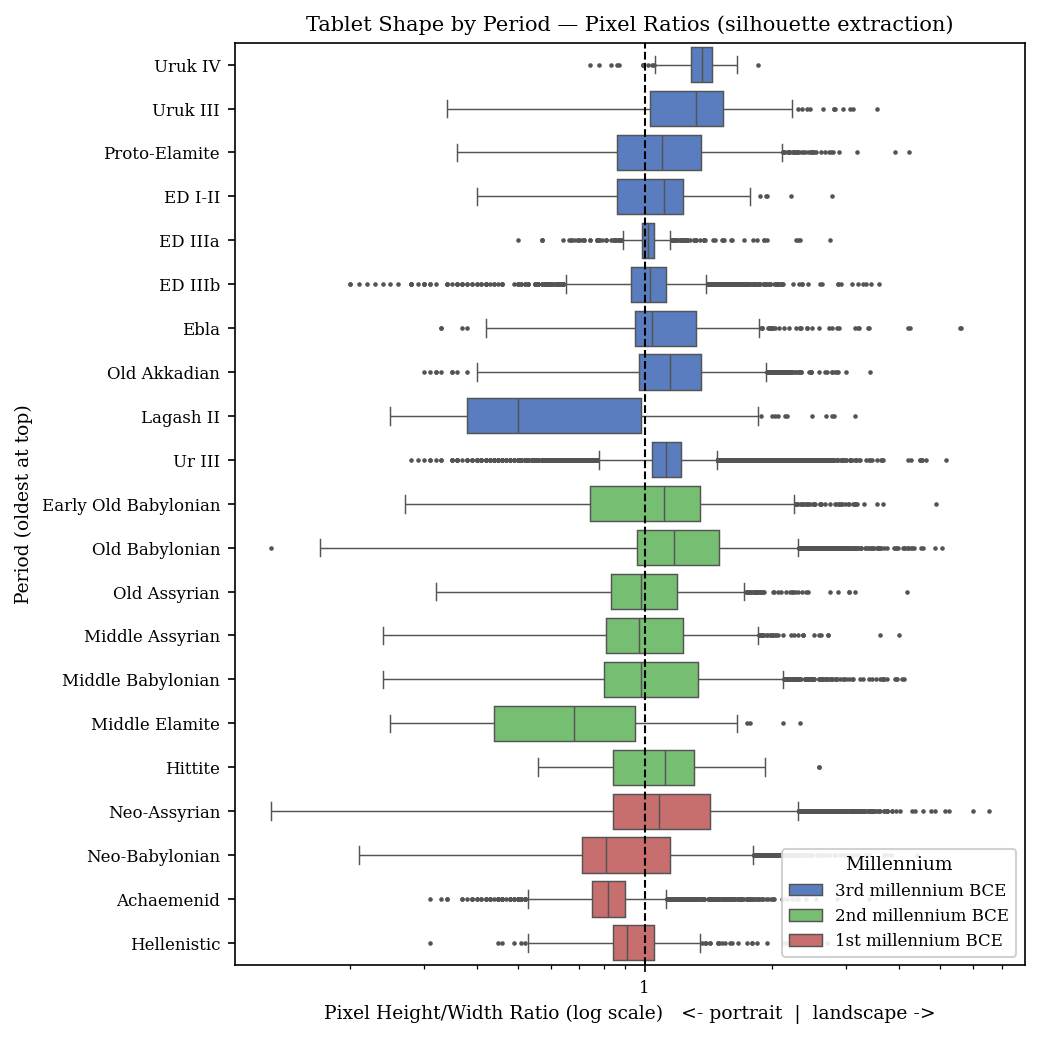

Saved: fig_pixel_ratio_by_period_log.pdf


In [5]:
fig, ax = plt.subplots(figsize=(7, 7))
sns.boxplot(y='Period_Name', x='hw_ratio', data=ratio_clean,
    order=PERIOD_CHRON_ORDER, hue='millennium', hue_order=MILLENNIUM_ORDER,
    palette=PALETTE, fliersize=1.2, linewidth=0.7, dodge=False, ax=ax)
ax.axvline(1, color='black', ls='--', lw=1)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda v, p: f'{v:.2g}'))
ax.set_xlabel('Pixel Height/Width Ratio (log scale)   <- portrait  |  landscape ->')
ax.set_ylabel('Period (oldest at top)')
ax.set_title('Tablet Shape by Period — Pixel Ratios (silhouette extraction)')
ax.legend(title='Millennium', loc='lower right', framealpha=0.9)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_pixel_ratio_by_period_log.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_pixel_ratio_by_period_log.pdf')

## 3. Statistical tests (same battery as notebook 2.2)

In [6]:
groups = [ratio_clean.loc[ratio_clean['Period_Name']==p,'hw_ratio'].values
          for p in PERIOD_CHRON_ORDER if ratio_clean['Period_Name'].eq(p).sum()>=5]
H, p_kw = kruskal(*groups)
N, k = sum(len(g) for g in groups), len(groups)
eta2 = (H - k + 1) / (N - k)

meds = ratio_clean.groupby('Period_Name')['hw_ratio'].median().reindex(PERIOD_CHRON_ORDER).dropna()
rho, p_s = spearmanr(np.arange(1, len(meds)+1), meds.values)

adm = ratio_clean[ratio_clean['Genre_Name']=='Administrative']
adm_meds = adm.groupby('Period_Name')['hw_ratio'].median().reindex(PERIOD_CHRON_ORDER).dropna()
rho_a, p_a = spearmanr(np.arange(1, len(adm_meds)+1), adm_meds.values)

adm_groups = [adm.loc[adm['Period_Name']==p,'hw_ratio'].values
              for p in adm_meds.index if len(adm.loc[adm['Period_Name']==p])>=5]
H_a, p_kw_a = kruskal(*adm_groups)
eta2_a = (H_a - len(adm_groups) + 1) / (sum(len(g) for g in adm_groups) - len(adm_groups))

print('=== PIXEL RATIO STATISTICS ===')
print(f'N = {len(ratio_clean):,}')
print(f'Kruskal-Wallis (all):  H={H:.2f}, p={p_kw:.2e}, eta2={eta2:.4f}')
print(f'Spearman (all):        rho={rho:.4f}, p={p_s:.2e}')
print(f'Spearman (admin only): rho={rho_a:.4f}, p={p_a:.2e}')
print(f'KW (admin only):       H={H_a:.2f}, p={p_kw_a:.2e}, eta2={eta2_a:.4f}')

=== PIXEL RATIO STATISTICS ===
N = 94,143
Kruskal-Wallis (all):  H=6414.07, p=0.00e+00, eta2=0.0679
Spearman (all):        rho=-0.5647, p=7.66e-03
Spearman (admin only): rho=-0.4175, p=6.70e-02
KW (admin only):       H=3690.33, p=0.00e+00, eta2=0.0822


In [7]:
def cliffs_delta_fast(x, y, max_n=2000, seed=42):
    rng = np.random.default_rng(seed)
    if len(x) > max_n: x = rng.choice(x, max_n, replace=False)
    if len(y) > max_n: y = rng.choice(y, max_n, replace=False)
    x, y = np.array(x), np.array(y)
    return (np.sum(x[:,None]>y[None,:])-np.sum(x[:,None]<y[None,:]))/(len(x)*len(y))

adj_pairs = list(zip(meds.index[:-1], meds.index[1:]))
alpha_b = 0.05 / len(adj_pairs)
rows = []
for p1, p2 in adj_pairs:
    g1 = ratio_clean.loc[ratio_clean['Period_Name']==p1,'hw_ratio'].values
    g2 = ratio_clean.loc[ratio_clean['Period_Name']==p2,'hw_ratio'].values
    if len(g1)<5 or len(g2)<5: continue
    _, pmw = mannwhitneyu(g1, g2, alternative='two-sided')
    d = cliffs_delta_fast(g1, g2)
    sig = '***' if pmw<alpha_b else ('*' if pmw<0.05 else 'ns')
    rows.append({'Period 1':p1,'Period 2':p2,'n1':len(g1),'n2':len(g2),
                 'p_MW':round(pmw,4),'cliffs_delta':round(d,3),'Bonferroni':sig})
adj_df = pd.DataFrame(rows)
print(f'Bonferroni alpha = {alpha_b:.5f}')
print(adj_df.to_string(index=False))

Bonferroni alpha = 0.00250
            Period 1             Period 2    n1    n2   p_MW  cliffs_delta Bonferroni
             Uruk IV             Uruk III   108   817 0.1357         0.088         ns
            Uruk III        Proto-Elamite   817   800 0.0000         0.237        ***
       Proto-Elamite              ED I-II   800   234 0.0801         0.075         ns
             ED I-II              ED IIIa   234   434 0.0008         0.157        ***
             ED IIIa              ED IIIb   434  1680 0.5693        -0.018         ns
             ED IIIb                 Ebla  1680   459 0.0001        -0.119        ***
                Ebla         Old Akkadian   459  2788 0.0000        -0.132        ***
        Old Akkadian            Lagash II  2788   594 0.0000         0.664        ***
           Lagash II               Ur III   594 27849 0.0000        -0.677        ***
              Ur III Early Old Babylonian 27849  1937 0.0000         0.083        ***
Early Old Babylonian       

In [8]:
def cv_table(df_sub, min_n=10):
    rows = []
    for p in PERIOD_CHRON_ORDER:
        g = df_sub.loc[df_sub['Period_Name']==p,'hw_ratio'].values
        if len(g) < min_n: continue
        rows.append({'Period':p,'n':len(g),
                     'Median':round(np.median(g),3),
                     'IQR':round(np.percentile(g,75)-np.percentile(g,25),3),
                     'CV':round(np.std(g,ddof=1)/np.mean(g),3)})
    return pd.DataFrame(rows)

cv_admin = cv_table(adm)
print('CV per period (administrative, pixel ratios):')
print(cv_admin.to_string(index=False))

CV per period (administrative, pixel ratios):
              Period     n  Median   IQR    CV
             Uruk IV   108   1.365 0.157 0.146
            Uruk III   783   1.330 0.495 0.286
       Proto-Elamite   800   1.100 0.503 0.391
             ED I-II   220   1.110 0.360 0.290
             ED IIIa   334   1.020 0.060 0.162
             ED IIIb  1369   1.030 0.110 0.216
                Ebla   456   1.040 0.370 0.487
        Old Akkadian  2507   1.160 0.375 0.290
           Lagash II   120   1.135 0.390 0.277
              Ur III 26442   1.120 0.170 0.238
Early Old Babylonian   353   1.140 0.320 0.277
      Old Babylonian  4522   1.100 0.460 0.334
        Old Assyrian    77   0.910 0.350 0.305
     Middle Assyrian   304   0.955 0.402 0.332
   Middle Babylonian  3965   0.940 0.500 0.350
      Middle Elamite    19   0.510 0.245 0.377
        Neo-Assyrian   477   1.210 0.770 0.401
      Neo-Babylonian  1391   0.750 0.200 0.402
          Achaemenid   473   0.790 0.150 0.300


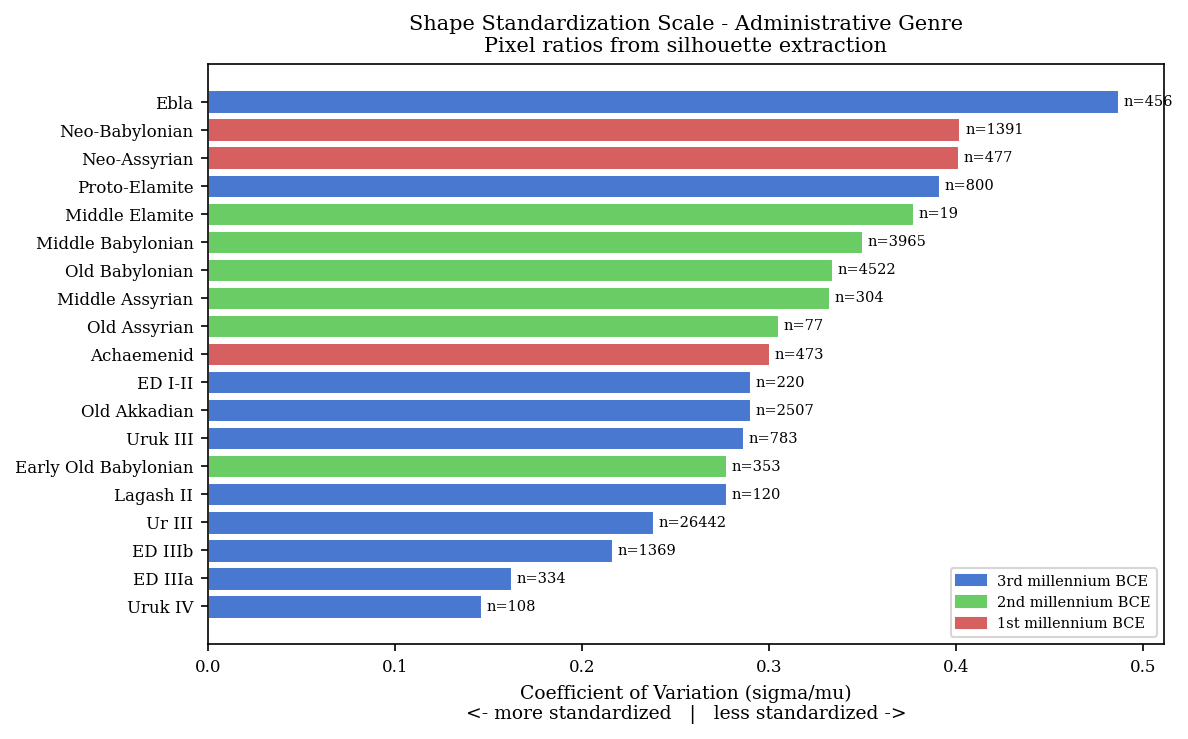

Saved: fig_pixel_cv_standardization.pdf


In [9]:
cv_sorted = cv_admin.sort_values('CV')
col = [PALETTE.get(
    ratio_clean.loc[ratio_clean['Period_Name']==p,'millennium'].mode().iloc[0]
    if not ratio_clean.loc[ratio_clean['Period_Name']==p,'millennium'].empty else '', '#888')
    for p in cv_sorted['Period']]
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(cv_sorted['Period'], cv_sorted['CV'], color=col, edgecolor='white', lw=0.5)
for bar, n in zip(bars, cv_sorted['n']):
    ax.text(bar.get_width()+0.003, bar.get_y()+bar.get_height()/2,
            f'n={n}', va='center', fontsize=7)
ax.set_xlabel('Coefficient of Variation (sigma/mu)\n<- more standardized   |   less standardized ->')
ax.set_title('Shape Standardization Scale - Administrative Genre\nPixel ratios from silhouette extraction')
handles = [mpatches.Patch(color=v, label=k) for k,v in PALETTE.items()]
ax.legend(handles=handles, loc='lower right', fontsize=7)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_pixel_cv_standardization.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_pixel_cv_standardization.pdf')

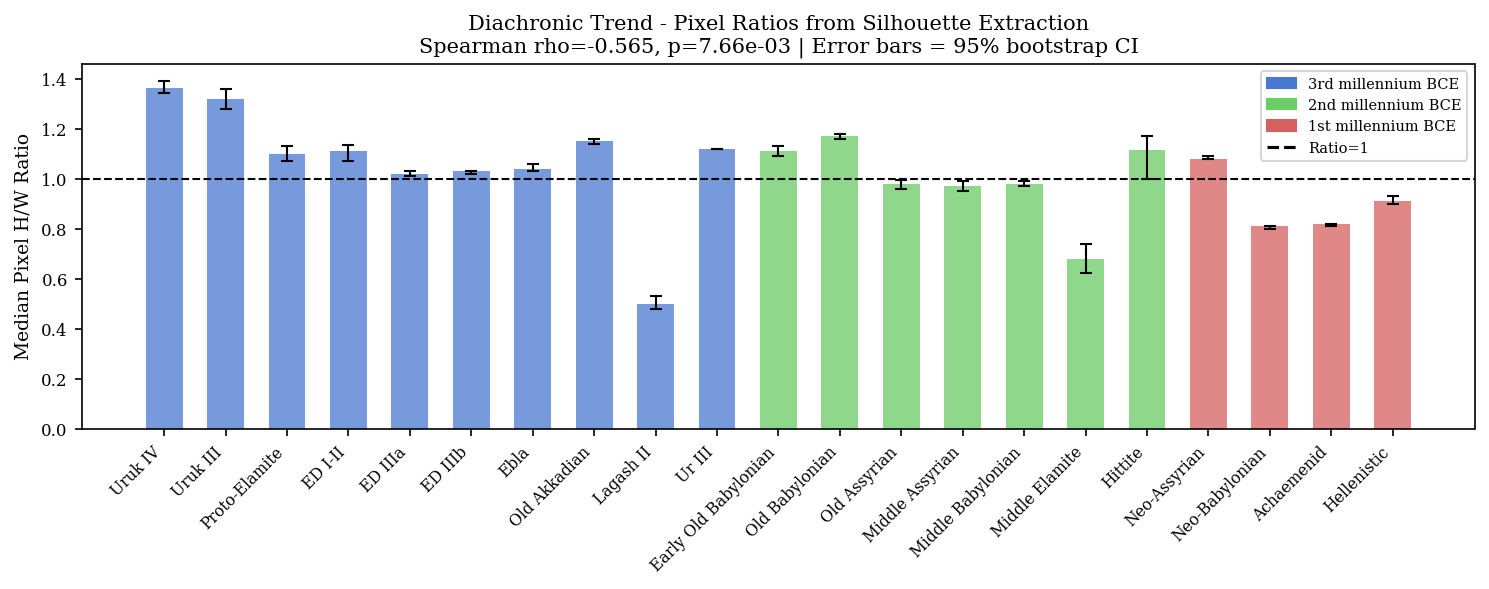

Saved: fig_pixel_diachronic_trend.pdf


In [10]:
np.random.seed(42)
ci_low, ci_high = [], []
for p in meds.index:
    vals = ratio_clean.loc[ratio_clean['Period_Name']==p,'hw_ratio'].values
    boot = [np.median(np.random.choice(vals, len(vals), replace=True)) for _ in range(5000)]
    ci_low.append(np.percentile(boot, 2.5))
    ci_high.append(np.percentile(boot, 97.5))
ci_low, ci_high = np.array(ci_low), np.array(ci_high)
p2m = ratio_clean.drop_duplicates('Period_Name').set_index('Period_Name')['millennium'].to_dict()
colors = [PALETTE.get(p2m.get(p,''), '#888') for p in meds.index]
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(meds))
ax.bar(x, meds.values, color=colors, alpha=0.75, width=0.6, zorder=2)
ax.errorbar(x, meds.values,
            yerr=[meds.values-ci_low, ci_high-meds.values],
            fmt='none', color='black', capsize=3, lw=1, zorder=3)
ax.axhline(1, color='black', ls='--', lw=1)
ax.set_xticks(x)
ax.set_xticklabels(meds.index, rotation=45, ha='right', fontsize=7.5)
ax.set_ylabel('Median Pixel H/W Ratio')
ax.set_title(
    'Diachronic Trend - Pixel Ratios from Silhouette Extraction\n'
    f'Spearman rho={rho:.3f}, p={p_s:.2e} | Error bars = 95% bootstrap CI'
)
handles = [mpatches.Patch(color=v, label=k) for k,v in PALETTE.items()]
handles.append(plt.Line2D([0],[0], color='black', ls='--', label='Ratio=1'))
ax.legend(handles=handles, loc='upper right', fontsize=7)
plt.tight_layout()
plt.savefig(f'{FIGURES_DIR}/fig_pixel_diachronic_trend.pdf', bbox_inches='tight')
plt.show()
print('Saved: fig_pixel_diachronic_trend.pdf')

In [11]:
np.random.seed(42)
rows = []
for p in PERIOD_CHRON_ORDER:
    g = ratio_clean.loc[ratio_clean['Period_Name']==p,'hw_ratio'].values
    if len(g) < 5: continue
    boot = [np.median(np.random.choice(g, len(g), replace=True)) for _ in range(5000)]
    rows.append({
        'Period':p, 'n':len(g),
        'Median':round(np.median(g),3),
        'CI_low':round(np.percentile(boot,2.5),3),
        'CI_high':round(np.percentile(boot,97.5),3),
        'IQR':round(np.percentile(g,75)-np.percentile(g,25),3),
        'CV':round(np.std(g,ddof=1)/np.mean(g),3),
        'Orientation':'portrait' if np.median(g)>1 else 'landscape'
    })
pix_summary = pd.DataFrame(rows)
pix_summary.to_csv(f'{FIGURES_DIR}/pixel_ratio_summary_stats.csv', index=False)
print(pix_summary.to_string(index=False))
print('Saved: pixel_ratio_summary_stats.csv')

              Period     n  Median  CI_low  CI_high   IQR    CV Orientation
             Uruk IV   108   1.365   1.345    1.390 0.157 0.146    portrait
            Uruk III   817   1.320   1.280    1.360 0.500 0.294    portrait
       Proto-Elamite   800   1.100   1.070    1.130 0.503 0.391    portrait
             ED I-II   234   1.110   1.070    1.135 0.370 0.291    portrait
             ED IIIa   434   1.020   1.010    1.030 0.068 0.203    portrait
             ED IIIb  1680   1.030   1.020    1.030 0.190 0.315    portrait
                Ebla   459   1.040   1.030    1.060 0.370 0.486    portrait
        Old Akkadian  2788   1.150   1.140    1.160 0.390 0.306    portrait
           Lagash II   594   0.500   0.480    0.530 0.598 0.631   landscape
              Ur III 27849   1.120   1.120    1.120 0.180 0.242    portrait
Early Old Babylonian  1937   1.110   1.090    1.130 0.610 0.441    portrait
      Old Babylonian 16814   1.170   1.160    1.180 0.540 0.346    portrait
        Old 